<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup guide](README.md)

# 01 · Count sign-ins once, including late arrivals

**Can a unique event table still report the wrong failure rate?** Read two paged
sign-in windows through the real worker. Two events become visible late. Compare
blind append, a sink keyed by event ID and an explicit fresh reference scan. The
worker's safety lag determines what the second scan can capture; SQL deduplication
determines how repeated events affect counts.

**Synthetic local HTTP data, real worker functions.** All event IDs, applications,
status codes and July 2026 timestamps are invented. The unchanged remote worker
builds Graph URLs, follows pages, extracts columns and computes its watermark.
Its existing client-factory seam points to loopback. No real users, IP addresses,
credentials or Microsoft account requests are involved. This bounded historical
exercise keeps replay cursors separate from any live ingestion state.

## Choose the safety lag

`LAG_MINUTES` is an integer from **0 through 20 minutes**. Default **10**; experiment
**0**. The first replay covers **4 July 2026, 10:00–10:30 UTC**, both endpoints
inclusive. The second starts at the worker's first watermark and ends at **10:45 UTC**,
also inclusive. Restart and run all after editing.

The worker subtracts the lag from the newest observed event, then floors the
result at the prior `since` value. Because these events predate execution, its
wall-clock clamp does not change that maximum. At zero lag, the inclusive `ge`
boundary still re-reads the newest event; it provides no duration of lookback.

In [1]:
LAG_MINUTES = 10  # integer 0–20 minutes; experiment 0 removes the lookback duration

In [2]:
import os
import sys
from datetime import UTC
from pathlib import Path
from tempfile import TemporaryDirectory

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = Path.cwd() if (Path.cwd() / "notebook_support.py").is_file() else Path.cwd() / "notebooks"
sys.path.insert(0, str(NOTEBOOK_DIR))
os.chdir(NOTEBOOK_DIR)
import haybarn
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib.ticker import MaxNLocator

from notebook_support import chart, cleanup, configure, prose, theme

fixture, previous_url = configure(LAG_MINUTES)
theme()
fixture_secret_directory = TemporaryDirectory(prefix="vgi-fixture-secrets-")
con = haybarn.connect(
    config={"secret_directory": fixture_secret_directory.name, "allow_persistent_secrets": False}
)
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == [], (
    "Fixture must start without SQL secrets"
)
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-signins/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-signins/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-signins/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/secret-isolation/vgi-azure-signins/notebooks/pyproject.toml.

## Connect the release and the local transport

Native **v0.4.0** supplies credential-free feed discovery. The Bun/Git launcher
pins public revision **`007b39947658892a6cd9c949c9d53faaf09d126e`**, installs that
revision's frozen lock, and registers its unchanged functions and catalog. Only
the injected HTTP client is replaced. Git, Bun and first-run downloads are required;
no parent worker checkout is needed.

The public dummy secret satisfies the function's lookup without authenticating.
The fixture serves sign-in metadata GETs only and rejects other endpoints.
User-principal-name and IP fields are absent, so their output columns remain NULL.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'azure' AS azure_release (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-azure-signins@v0.4.0');
-- Remote source 007b39947658892a6cd9c949c9d53faaf09d126e with its frozen Bun lock.
ATTACH 'azure' AS azure_fixture (TYPE vgi, LOCATION 'bash launch_fixture.sh');
CREATE TEMPORARY SECRET notebook_fixture (TYPE azure_graph,
    TENANT_ID '00000000-0000-0000-0000-000000000001',
    CLIENT_ID '00000000-0000-0000-0000-000000000002',
    CLIENT_SECRET 'synthetic-not-a-credential');
SELECT * FROM azure_release.main.audit_feeds;

,feed,table_function,graph_endpoint,description
0,sign-in logs,signin_logs,/auditLogs/signIns,Microsoft Entra ID interactive sign-in events ...
1,directory audit logs,audit_logs,/auditLogs/directoryAudits,Microsoft Entra ID directory audit / activity ...


In [4]:
fixture_secrets = con.execute(
    "SELECT name, persistent, storage FROM duckdb_secrets() ORDER BY name"
).fetchall()
assert fixture_secrets == [("notebook_fixture", False, "memory")], (
    "Only the public temporary fixture secrets may exist"
)

In [5]:
prose(
    f"**Local synthetic Graph fixture:** `{fixture.url}`. Analytical reads use "
    "`azure_fixture.main.signin_logs`. Native release discovery uses `azure_release`. "
    "All cursors below belong only to this historical replay."
)

**Local synthetic Graph fixture:** `http://127.0.0.1:59105`. Analytical reads use `azure_fixture.main.signin_logs`. Native release discovery uses `azure_release`. All cursors below belong only to this historical replay.

## Apply the first window, then keep its replay cursor

Materialize each API call before capturing results for display. Ordinary in-memory
tables survive JupySQL cursor changes. The marker is control information, not an
event. The local sink uses an event-ID primary key for this one synthetic feed;
a multi-tenant, multi-feed sink also needs that source scope in its key.

In [6]:
%%sql
CREATE TABLE first_batch AS
SELECT * FROM azure_fixture.main.signin_logs(
    since := '2026-07-04T10:00:00Z', until := '2026-07-04T10:30:00Z',
    page_size := 3, lag_minutes := {{LAG_MINUTES}});
CREATE TABLE event_sink (
    id VARCHAR PRIMARY KEY, created_date_time VARCHAR, app_display_name VARCHAR, status VARCHAR);
INSERT INTO event_sink SELECT id, created_date_time, app_display_name, status
FROM first_batch WHERE _row_kind IS NULL;
CREATE TABLE replay_cursor AS
SELECT 'signin_logs' AS feed, _watermark_next AS watermark
FROM first_batch WHERE _row_kind = 'marker';
SELECT * FROM event_sink ORDER BY created_date_time, id;

,id,created_date_time,app_display_name,status
0,s01,2026-07-04T10:00:00Z,Portal,0
1,s02,2026-07-04T10:05:00Z,Portal,0
2,s03,2026-07-04T10:10:00Z,Batch,50126
3,s04,2026-07-04T10:15:00Z,Portal,0
4,s05,2026-07-04T10:20:00Z,Batch,0
5,s06,2026-07-04T10:25:00Z,Portal,0
6,s07,2026-07-04T10:30:00Z,Batch,None


In [7]:
%%sql first_cursor <<
SELECT watermark,
       (SELECT max(created_date_time::TIMESTAMP) FROM first_batch WHERE _row_kind IS NULL) AS newest_event
FROM replay_cursor;

In [8]:
display(first_cursor)
assert len(first_cursor) == 1
watermark = first_cursor.iloc[0].watermark
watermark_sql = "'" + watermark.replace("'", "''") + "'"
prose(
    f"The first replay resumes at **{watermark}**, with a configured lag of "
    f"**{LAG_MINUTES} minutes**. Events are not assumed to arrive in timestamp order."
)

,watermark,newest_event
0,2026-07-04T10:20:00.000Z,2026-07-04 10:30:00


The first replay resumes at **2026-07-04T10:20:00.000Z**, with a configured lag of **10 minutes**. Events are not assumed to arrive in timestamp order.

## Make late events visible, then replay from the watermark

The fixture now exposes two previously unavailable events whose timestamps fall
inside the first window, plus newer events. These are additional immutable events,
not edits to earlier records. The worker follows opaque page links and may emit
old IDs again because the lower bound is inclusive.

Before ignoring conflicting IDs, verify that repeated IDs have unchanged payloads.
That is the condition under which `ON CONFLICT DO NOTHING` is appropriate here.

In [9]:
fixture.publish_late_events()

In [10]:
%%sql
CREATE TABLE second_batch AS
SELECT * FROM azure_fixture.main.signin_logs(
    since := {{watermark_sql}}, until := '2026-07-04T10:45:00Z',
    page_size := 3, lag_minutes := {{LAG_MINUTES}});
SELECT id, created_date_time, app_display_name, status
FROM second_batch WHERE _row_kind IS NULL ORDER BY created_date_time, id;

,id,created_date_time,app_display_name,status
0,s05,2026-07-04T10:20:00Z,Batch,0
1,s08,2026-07-04T10:23:00Z,Portal,50126
2,s06,2026-07-04T10:25:00Z,Portal,0
3,s09,2026-07-04T10:27:00Z,Batch,50126
4,s07,2026-07-04T10:30:00Z,Batch,None
5,s10,2026-07-04T10:35:00Z,Portal,0
6,s11,2026-07-04T10:40:00Z,Batch,0


In [11]:
%%sql batch_safety <<
SELECT count(*) = count(DISTINCT id) AND bool_and(id IS NOT NULL AND id <> '') AS unique_ids,
       (SELECT count(*) FROM second_batch WHERE _row_kind = 'marker') = 1 AS one_marker,
       NOT EXISTS (
         SELECT 1 FROM second_batch b JOIN event_sink s USING(id)
         WHERE b.created_date_time IS DISTINCT FROM s.created_date_time
            OR b.app_display_name IS DISTINCT FROM s.app_display_name
            OR b.status IS DISTINCT FROM s.status) AS repeated_payloads_unchanged
FROM second_batch WHERE _row_kind IS NULL;

In [12]:
display(batch_safety)
assert batch_safety.notna().all().all() and batch_safety.all().all(), "Unsafe event batch"

,unique_ids,one_marker,repeated_payloads_unchanged
0,True,True,True


## Deduplicate by ID and compare with a fresh reference

Apply rows before updating the replay cursor. This notebook demonstrates the
sequence in memory; a production sink must commit both atomically on a single
transactional connection. A fresh scan of the revised fixture is an explicit
validation request, not part of routine incremental ingestion.

In [13]:
%%sql
INSERT INTO event_sink
SELECT id, created_date_time, app_display_name, status
FROM second_batch WHERE _row_kind IS NULL
ON CONFLICT (id) DO NOTHING;
UPDATE replay_cursor SET watermark =
    (SELECT _watermark_next FROM second_batch WHERE _row_kind = 'marker')
WHERE feed = 'signin_logs';
CREATE TABLE reference_batch AS
SELECT * FROM azure_fixture.main.signin_logs(
    since := '2026-07-04T10:00:00Z', until := '2026-07-04T10:45:00Z',
    page_size := 3, lag_minutes := {{LAG_MINUTES}});
CREATE TABLE fresh_reference AS
SELECT id, created_date_time, app_display_name, status FROM reference_batch WHERE _row_kind IS NULL;
CREATE TABLE blind_append AS
SELECT id, created_date_time, app_display_name, status FROM first_batch WHERE _row_kind IS NULL
UNION ALL
SELECT id, created_date_time, app_display_name, status FROM second_batch WHERE _row_kind IS NULL;
CREATE TABLE missing_events AS
SELECT * FROM fresh_reference WHERE id NOT IN (SELECT id FROM event_sink);
SELECT * FROM missing_events ORDER BY created_date_time, id;

,id,created_date_time,app_display_name,status


In [14]:
%%sql capture_summary <<
SELECT (SELECT count(*) FROM event_sink) AS sink_events,
       (SELECT count(*) FROM fresh_reference) AS reference_events,
       (SELECT count(*) FROM missing_events) AS missed_events,
       (SELECT count(*) - count(DISTINCT id) FROM blind_append) AS duplicate_deliveries;

In [15]:
capture = capture_summary.iloc[0]
if capture.missed_events == 0:
    conclusion = "The sink contains every event in the fresh reference."
else:
    conclusion = (
        f"The unique sink misses **{int(capture.missed_events)} reference event(s)**; "
        "deduplication cannot recover events outside the fetched window."
    )
prose(
    f"The sink has **{int(capture.sink_events)} events**, compared with "
    f"**{int(capture.reference_events)}** in the reference. Blind append retains "
    f"**{int(capture.duplicate_deliveries)} duplicate deliveries**. {conclusion}"
)

The sink has **11 events**, compared with **11** in the reference. Blind append retains **3 duplicate deliveries**. The sink contains every event in the fresh reference.

## See which events fall behind the replay boundary

Place all reference events by timestamp and application. Classify an event as a
late arrival when it was absent from the first response but is no newer than that
response's maximum timestamp. Marker shape distinguishes later visibility from
initial observations; color shows whether late arrivals reached the sink.

In [16]:
%%sql timeline <<
SELECT r.id, r.created_date_time::TIMESTAMP AS event_time, r.app_display_name AS application,
       CASE WHEN f.id IS NOT NULL THEN 'Seen in first scan'
            WHEN r.created_date_time::TIMESTAMP <=
                 (SELECT max(created_date_time::TIMESTAMP) FROM first_batch WHERE _row_kind IS NULL)
              THEN CASE WHEN s.id IS NULL THEN 'Late arrival missed' ELSE 'Late arrival captured' END
            ELSE 'Newer event' END AS visibility
FROM fresh_reference r
LEFT JOIN first_batch f ON r.id = f.id
LEFT JOIN event_sink s ON r.id = s.id
ORDER BY event_time, r.id;

/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/ipykernel_78706/1690891192.py:38: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  timeline.event_time.min() - pd.Timedelta(minutes=3), timeline.event_time.max() + pd.Timedelta(minutes=4)
findfont: Failed to find font weight semibold for Arial, now using 700.


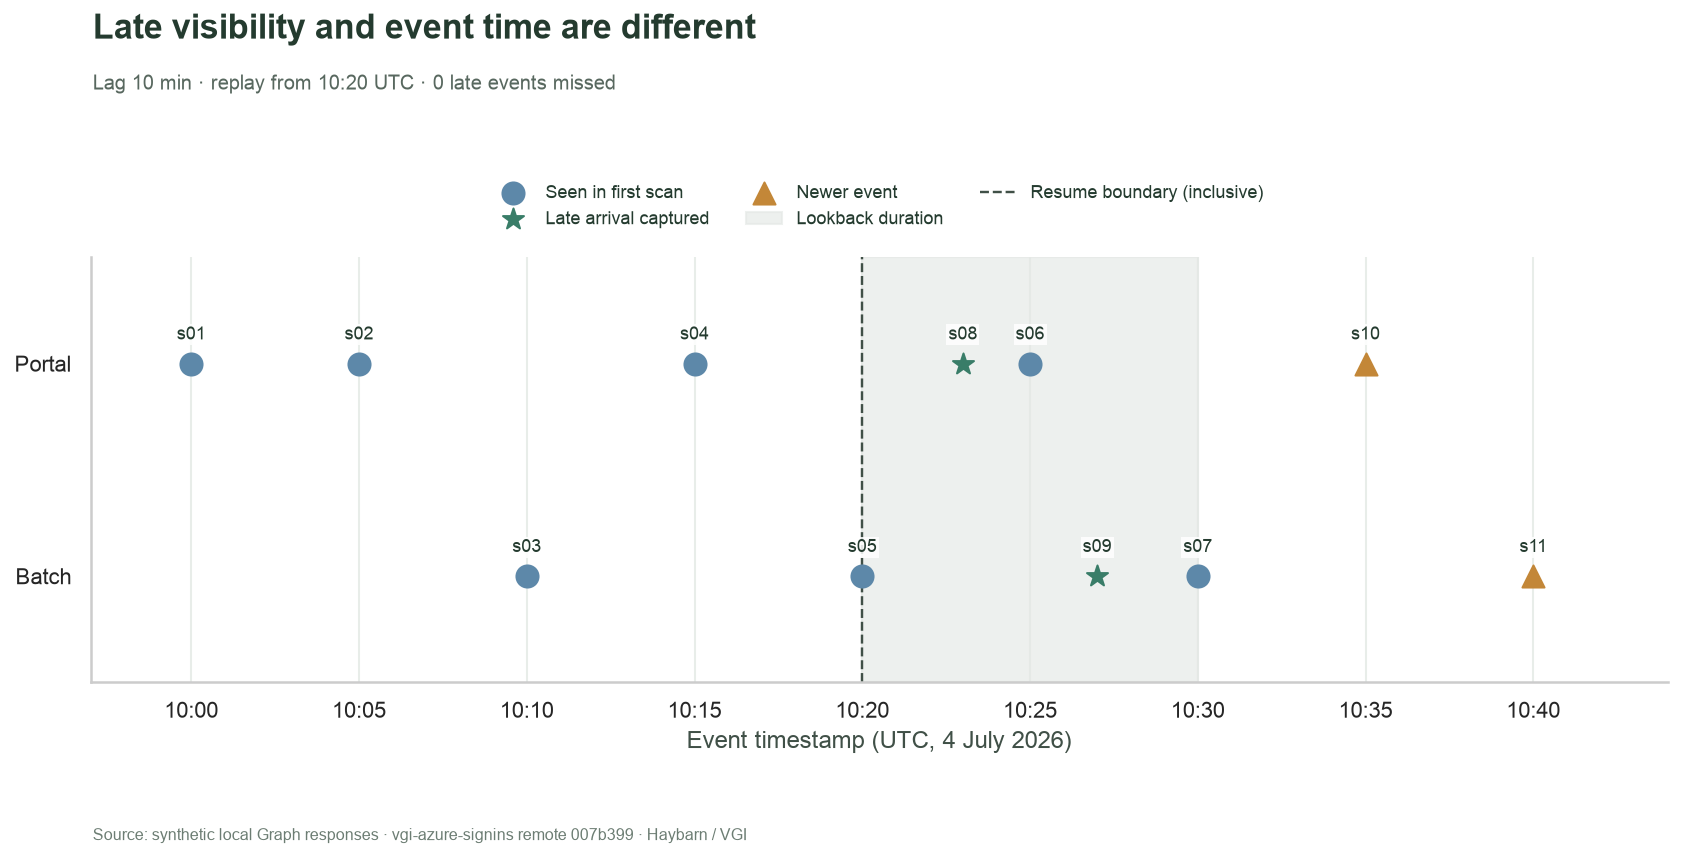

In [17]:
styles = {
    "Seen in first scan": ("#5D88A9", "o"),
    "Late arrival captured": ("#397D68", "*"),
    "Late arrival missed": ("#B65D51", "X"),
    "Newer event": ("#C38738", "^"),
}
timeline["event_time"] = pd.to_datetime(timeline.event_time, utc=True)
app_positions = {name: i for i, name in enumerate(sorted(timeline.application.unique()))}
fig, ax = plt.subplots(figsize=(12, 6))
for label, group in timeline.groupby("visibility", sort=False):
    color, marker = styles[label]
    ax.scatter(
        group.event_time,
        group.application.map(app_positions),
        label=label,
        color=color,
        marker=marker,
        s=120,
        zorder=4,
    )
    for row in group.itertuples():
        ax.annotate(
            row.id,
            (row.event_time, app_positions[row.application]),
            xytext=(0, 12),
            textcoords="offset points",
            ha="center",
            fontsize=9,
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 1, "alpha": 0.85},
        )
resume = pd.to_datetime(watermark).to_pydatetime()
newest = pd.to_datetime(first_cursor.iloc[0].newest_event, utc=True)
ax.axvspan(resume, newest, color="#E4E8E5", alpha=0.65, label="Lookback duration")
ax.axvline(resume, color="#405047", linestyle="--", linewidth=1.2, label="Resume boundary (inclusive)")
ax.set_yticks(list(app_positions.values()), labels=list(app_positions))
ax.set_ylim(-0.5, len(app_positions) - 0.5)
ax.set_xlim(
    timeline.event_time.min() - pd.Timedelta(minutes=3), timeline.event_time.max() + pd.Timedelta(minutes=4)
)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=UTC))
ax.set_xlabel("Event timestamp (UTC, 4 July 2026)")
ax.grid(axis="y", visible=False)
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.03), fontsize=9)
chart(
    fig,
    "Late visibility and event time are different",
    f"Lag {LAG_MINUTES} min · replay from {resume.strftime('%H:%M')} UTC · "
    f"{int(capture.missed_events)} late events missed",
)

## Compare event counts and measured failure rates

For sign-ins, numeric status **0 means success** and a positive code means failure.
Missing or invalid status stays **unknown**, excluded from the rate denominator
and counted alongside it. These are synthetic error codes, not a risk score or
an inference about a person. Directory audit status uses different semantics and
is not mixed into this calculation.

Compute failure percentage as `100 × failures / (successes + failures)`. Repeated
records can change its denominator and numerator; missing late failures can make
an incomplete sink look healthier.

In [18]:
%%sql comparison <<
WITH versions AS (
  SELECT 1 AS ordinal, 'Blind append' AS method, status FROM blind_append
  UNION ALL SELECT 2, 'ID-dedup sink', status FROM event_sink
  UNION ALL SELECT 3, 'Fresh reference', status FROM fresh_reference
), typed AS (
  SELECT *, try_cast(status AS INTEGER) AS error_code FROM versions
), counts AS (
  SELECT ordinal, method, count(*) AS event_rows,
         count(*) FILTER (WHERE error_code = 0) AS successes,
         count(*) FILTER (WHERE error_code > 0) AS failures,
         count(*) FILTER (WHERE error_code IS NULL OR error_code < 0) AS unknown_status
  FROM typed GROUP BY ordinal, method
)
SELECT *, successes + failures AS known_status,
       100.0 * failures / nullif(successes + failures,0) AS failure_pct
FROM counts ORDER BY ordinal;

In [19]:
display(comparison)
sink_rate = comparison.loc[comparison.method == "ID-dedup sink"].iloc[0]
reference_rate = comparison.loc[comparison.method == "Fresh reference"].iloc[0]
prose(
    f"The sink reports **{sink_rate.failure_pct:.2f}%** failures among "
    f"**{int(sink_rate.known_status)} known outcomes**, with **{int(sink_rate.unknown_status)} unknown**. "
    f"The fresh reference reports **{reference_rate.failure_pct:.2f}%** among "
    f"**{int(reference_rate.known_status)} known outcomes**: a sink-minus-reference difference of "
    f"**{sink_rate.failure_pct - reference_rate.failure_pct:+.2f} percentage points**."
)

,ordinal,method,event_rows,successes,failures,unknown_status,known_status,failure_pct
0,1,Blind append,14,9,3,2,12,25.0
1,2,ID-dedup sink,11,7,3,1,10,30.0
2,3,Fresh reference,11,7,3,1,10,30.0


The sink reports **30.00%** failures among **10 known outcomes**, with **1 unknown**. The fresh reference reports **30.00%** among **10 known outcomes**: a sink-minus-reference difference of **+0.00 percentage points**.

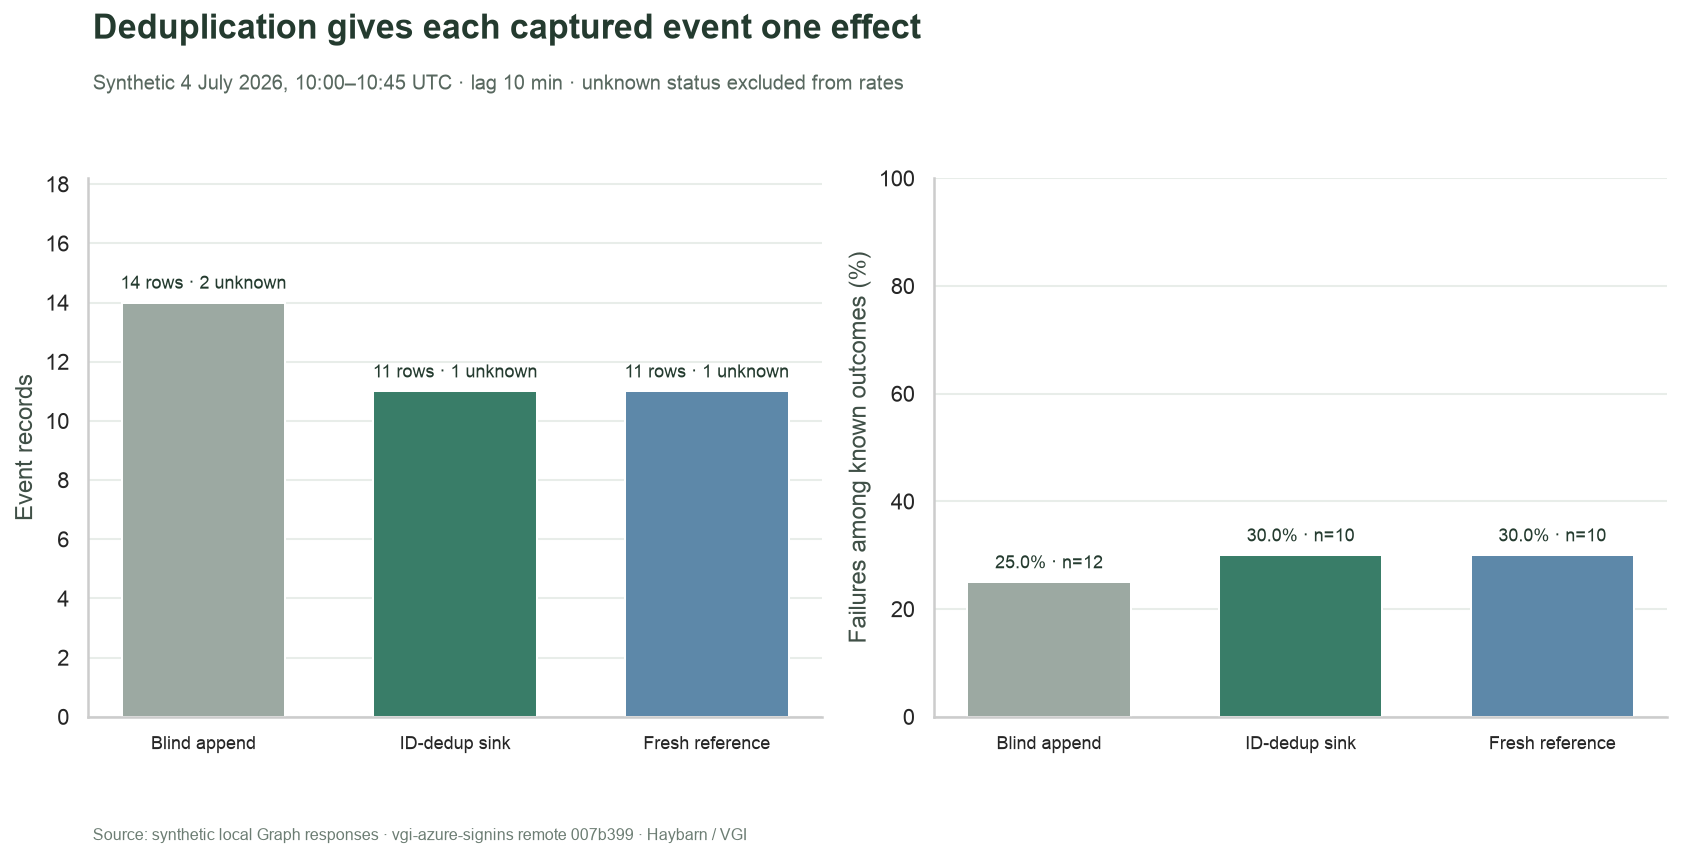

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
colors = ["#9CA9A2", "#397D68", "#5D88A9"]
bars = axes[0].bar(comparison.method, comparison.event_rows, color=colors, width=0.65)
axes[0].bar_label(
    bars,
    labels=[
        f"{int(r)} rows · {int(u)} unknown"
        for r, u in zip(comparison.event_rows, comparison.unknown_status, strict=True)
    ],
    fontsize=9,
    padding=5,
)
axes[0].set_ylim(0, comparison.event_rows.max() * 1.3)
axes[0].set_ylabel("Event records")
axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))
bars = axes[1].bar(comparison.method, comparison.failure_pct, color=colors, width=0.65)
axes[1].bar_label(
    bars,
    labels=[
        f"{v:.1f}% · n={int(k)}" for v, k in zip(comparison.failure_pct, comparison.known_status, strict=True)
    ],
    fontsize=9,
    padding=5,
)
axes[1].set_ylim(0, 100)
axes[1].set_ylabel("Failures among known outcomes (%)")
for ax in axes:
    ax.tick_params(axis="x", labelsize=9)
    ax.grid(axis="x", visible=False)
title = (
    "A unique sink can still miss late events"
    if capture.missed_events
    else "Deduplication gives each captured event one effect"
)
chart(
    fig,
    title,
    f"Synthetic 4 July 2026, 10:00–10:45 UTC · lag {LAG_MINUTES} min · unknown status excluded from rates",
)

## Validate application, then assess completeness separately

Application checks should pass at either lag setting. They establish that the
sink contains exactly the distinct delivered rows, repeats were safe to ignore,
and marker/cursor handling is correct. Completeness against the full reference is
a separate result above; a passing primary-key check cannot establish it.

In [21]:
%%sql checks <<
SELECT 'one strict marker per scan' AS check_name, bool_and(marker_count = 1) AS passed FROM (
  SELECT count(*) AS marker_count FROM first_batch WHERE _row_kind = 'marker'
  UNION ALL SELECT count(*) FROM second_batch WHERE _row_kind = 'marker'
  UNION ALL SELECT count(*) FROM reference_batch WHERE _row_kind = 'marker')
UNION ALL SELECT 'marker business fields NULL', bool_and(id IS NULL AND created_date_time IS NULL
       AND app_display_name IS NULL AND user_principal_name IS NULL AND ip_address IS NULL AND status IS NULL)
       FROM (SELECT * FROM first_batch UNION ALL SELECT * FROM second_batch UNION ALL SELECT * FROM reference_batch)
       WHERE _row_kind = 'marker'
UNION ALL SELECT 'first watermark follows lag and floor',
       (SELECT _watermark_next::TIMESTAMP FROM first_batch WHERE _row_kind = 'marker') = greatest(
       (SELECT max(created_date_time::TIMESTAMP) FROM first_batch WHERE _row_kind IS NULL)
       - {{LAG_MINUTES}} * INTERVAL '1 minute', TIMESTAMP '2026-07-04 10:00:00')
UNION ALL SELECT 'sink equals distinct delivered payloads', NOT EXISTS (
       (SELECT * FROM event_sink EXCEPT SELECT DISTINCT * FROM blind_append)
       UNION ALL (SELECT DISTINCT * FROM blind_append EXCEPT SELECT * FROM event_sink))
UNION ALL SELECT 'sink payloads exist in reference', NOT EXISTS (
       SELECT * FROM event_sink EXCEPT SELECT * FROM fresh_reference)
UNION ALL SELECT 'cursor matches applied batch',
       (SELECT watermark FROM replay_cursor WHERE feed = 'signin_logs') =
       (SELECT _watermark_next FROM second_batch WHERE _row_kind = 'marker')
UNION ALL SELECT 'second scan respects inclusive lower bound', bool_and(
       created_date_time::TIMESTAMP >= {{watermark_sql}}::TIMESTAMP)
       FROM second_batch WHERE _row_kind IS NULL;

In [22]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), "A replay application relationship failed"
assert (comparison.event_rows == comparison.successes + comparison.failures + comparison.unknown_status).all()
assert sum(r["offset"] == 0 for r in fixture.requests) == 3, "Each materialized scan must start once"
prose(
    f"**All {len(checks)} SQL relationships passed.** The worker made "
    f"**{len(fixture.requests)} local metadata GETs** across three scans; pages preserved their "
    "filtered snapshot. Outcome counts partition every representation. "
    "These checks do not promise recovery of events older than the selected lookback."
)

,check_name,passed
0,one strict marker per scan,True
1,marker business fields NULL,True
2,first watermark follows lag and floor,True
3,sink equals distinct delivered payloads,True
4,sink payloads exist in reference,True
5,cursor matches applied batch,True
6,second scan respects inclusive lower bound,True


**All 7 SQL relationships passed.** The worker made **10 local metadata GETs** across three scans; pages preserved their filtered snapshot. Outcome counts partition every representation. These checks do not promise recovery of events older than the selected lookback.

## Experiment: remove the lookback duration

Change **`LAG_MINUTES = 10` to `LAG_MINUTES = 0`**, restart, and run all. Predict that
the sink remains unique but misses late events older than the first scan's maximum.
Compare the resume boundary, missing-event table, and failure-rate denominator.
The first scan and fresh reference should stay unchanged; application checks
should pass even when reference completeness fails.

The example shows one late-arrival pattern. Ten minutes captures this fixture's
late events without guaranteeing that all real delays fit that window. It also
assumes immutable event payloads, rejects conflicting repeats, and provides no
crash recovery. Restore **10** for the default; the [guide](README.md) gives the
separate experiment command.

In [23]:
con.close()
fixture_secret_directory.cleanup()
cleanup(fixture, previous_url)

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)